# The 1926 capillary data of Herschel and Bulkley in modern variables

In 1926 Winslow Herschel and Ronald Bulkley measured how fast benzene solutions of rubber flowed through glass capillaries under a range of driving pressures. The relation they printed, a power law in pressure with an empirical "initial pressure", is the ancestor of the Herschel–Bulkley (HB) law $\sigma = \sigma_y + K\dot\gamma^{\,n}$ that is now used for drilling muds, concrete, foods and foams. Yet their paper contains no shear stress, no shear rate and no yield stress. In this notebook we take their own numbers, convert them from the units of 1926 into wall shear stress and wall shear rate, apply the rheometric inversion that was published only three years later, and refit them with the modern law. The exercise shows, with real data, why the review calls the 1926 relation *a correlation, not a constitutive law*, and why the rubber solutions that gave the model its name turn out to be shear-thinning liquids whose data give no evidence of a yield stress.

### Where this is in the review
- **Sec. II** (The 1926 work of Herschel and Bulkley), subsections A–D; especially **Sec. II B** (the 1926 papers) and **Sec. II C** (a correlation, not a constitutive law).
- **Eq. (1)**: the 1926 correlation $d^4(P-P_0)^a/(Lq) = I$. **Eq. (2)**: the exact capillary flow rate of a power-law liquid. **Eq. (3)**: the modern HB law. **Eqs. (23)–(25)**: the pipe flow rate near and far above onset (Sec. VII C).
- **Fig. 1** (the 1926 data replotted), the left strip of **Fig. 3**, and **Table III** (rheometric inversion, 1927–1952, as the first milestone).
- Supplementary Note **S15 A** (unit conversions) and **S19** (nomenclature: $P$, $P_0$, $I$, $a$).
- Script `scripts/fig01_hb1926.py`; data `data/hb1926_table3.csv`, `data/hb1926_table4.csv`, `data/hb1926_reanalysis.json`.

### Learning objectives
After working through this notebook you should be able to
1. convert the 1926 units (gram-force per square centimeter, cubic centimeters per second) into SI units;
2. compute the wall shear stress of a capillary from the pressure drop by a force balance, and the apparent (Newtonian) wall shear rate from the flow rate;
3. explain and apply the Weissenberg–Rabinowitsch–Mooney correction that turns the apparent wall shear rate into the true one;
4. fit the HB law to wall data with a physical constraint $\sigma_y \ge 0$, and recognize when the data do not require a yield stress;
5. state three reasons why the 1926 relation is an instrument correlation rather than a local constitutive law.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))

import hbstyle as hs   # house style, palette C and HB helper functions (we never call hs.save)
C = hs.C
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())
from scipy.optimize import least_squares
from hb_prediction import pipe_flux     # exact no-slip HB pipe flow rate (SI units)

data folder found: True


## 1. The data of 1926 and their units

Table III of the Kolloid-Zeitschrift paper lists, for each solution and capillary, the flow rate $q$ (cm$^3$ s$^{-1}$) measured at a "corrected" driving pressure $P$ (the pressure head corrected for kinetic-energy and end losses), in **gram-force per square centimeter** (g cm$^{-2}$ in the paper). The repository contains the measurements made in the two Bingham viscometers at 30 °C:

| Viscometer | diameter $d$ (cm) | length $L$ (cm) |
|---|---|---|
| Bingham Nr. 3 (`B3`) | 0.1018 | 10.0 |
| Bingham Nr. 2 (`B2`) | 0.0689 | 14.6 |

A gram-force is the weight of one gram under standard gravity, $g_n = 9.80665$ m s$^{-2}$, so

$$1\ \mathrm{gf\,cm^{-2}} = \frac{10^{-3}\ \mathrm{kg}\times 9.80665\ \mathrm{m\,s^{-2}}}{10^{-4}\ \mathrm{m^2}} = 98.0665\ \mathrm{Pa}.$$

In [2]:
t3 = pd.read_csv(DATA / "hb1926_table3.csv")
print(t3.shape[0], "measurements")
t3.head()

113 measurements


,instrument,conc_pct,P_g_per_cm2,q_cm3_per_s
0,B3,0.599,84.9,0.490
1,B3,0.599,78.1,0.442
2,B3,0.599,70.8,0.393
3,B3,0.599,65.2,0.361
4,B3,0.599,58.9,0.318


In [3]:
# One row per (instrument, concentration) series: number of points and ranges
summary = (t3.groupby(["instrument", "conc_pct"])
             .agg(points=("P_g_per_cm2", "size"),
                  P_min=("P_g_per_cm2", "min"), P_max=("P_g_per_cm2", "max"),
                  q_min=("q_cm3_per_s", "min"), q_max=("q_cm3_per_s", "max")))
summary

points  P_min  P_max  q_min  q_max
instrument conc_pct                                    
B2         0.399         15   20.1  226.0  0.023  0.350
           0.692         14   24.4  259.3  0.010  0.186
           1.004         10  212.8  545.7  0.069  0.251
           1.190          9  124.4  620.7  0.021  0.204
B3         0.599          9   12.9   84.9  0.053  0.490
           0.693          9   22.4   95.6  0.074  0.437
           0.800         11   39.6  118.2  0.104  0.423
           0.993         12   20.0  165.6  0.028  0.437
           1.107         13   21.2  201.0  0.021  0.432
           1.210         11   63.3  233.6  0.068  0.446

In [4]:
# Capillary dimensions (cm) and the unit conversion
DIM = {"B3": (0.1018, 10.0), "B2": (0.0689, 14.6)}     # (d, L) in cm
GF_PER_CM2 = 1e-3 * 9.80665 / 1e-4                     # Pa per gf/cm^2
print(f"1 gf/cm^2 = {GF_PER_CM2:.4f} Pa")
print(f"pressure range in Table III: {t3.P_g_per_cm2.min():.1f}-{t3.P_g_per_cm2.max():.1f} gf/cm^2 "
      f"= {t3.P_g_per_cm2.min()*GF_PER_CM2/1e3:.2f}-{t3.P_g_per_cm2.max()*GF_PER_CM2/1e3:.1f} kPa")

1 gf/cm^2 = 98.0665 Pa
pressure range in Table III: 12.9-620.7 gf/cm^2 = 1.27-60.9 kPa


## 2. The 1926 correlation, Eq. (1)

When Herschel and Bulkley plotted $\log q$ against $\log P$, the points fell on straight lines. They wrote the result as

$$\frac{d^4\,(P-P_0)^{a}}{L\,q} = I, \qquad\text{that is}\qquad q = \frac{d^4}{L\,I}\,(P-P_0)^a, \tag{1}$$

where $I$ is "a purely empirical constant". The paper prints the exponent as $n$ and the initial pressure as $K$; the review writes them as $a$ and $P_0$ to avoid confusion with the modern flow index and consistency, and so do we. Their Table IV lists the constants of 22 such fits (two Ostwald and two Bingham viscometers).

In [5]:
t4 = pd.read_csv(DATA / "hb1926_table4.csv").rename(
    columns={"exponent_n": "a", "K_g_per_cm2": "P0_gf_per_cm2"})
print(f"{len(t4)} fits; a ranges from {t4.a.min()} to {t4.a.max()}; "
      f"P0 = 0 in {(t4.P0_gf_per_cm2 == 0).sum()} of them")
t4

22 fits; a ranges from 1.11 to 1.51; P0 = 0 in 20 of them


,instrument,capillary_diameter_cm,conc_pct,a,I,P0_gf_per_cm2
0,Ostwald 1,0.0811,0.204,1.11,0.00083,0
1,Ostwald 1,0.0811,0.401,1.15,0.00211,0
2,Ostwald 1,0.0811,0.585,1.19,0.00442,0
3,Ostwald 1,0.0811,0.793,1.27,0.01114,0
4,Ostwald 1,0.0811,0.993,1.40,0.03459,0
5,Ostwald 1,0.0811,1.190,1.51,0.09120,0
6,Ostwald 2,0.0840,0.204,1.11,0.00083,0
7,Ostwald 2,0.0840,0.401,1.15,0.00210,0
8,Ostwald 2,0.0840,0.585,1.19,0.00425,0
9,Ostwald 2,0.0840,0.793,1.27,0.01033,0


In [6]:
def q_1926(P, d, L, a, I, P0):
    """Flow rate (cm^3/s) from the 1926 correlation, Eq. (1); P and P0 in gf/cm^2, d and L in cm."""
    return d**4 * (P - P0)**a / (L * I)

def table4_row(inst, conc):
    name = {"B3": "Bingham 3", "B2": "Bingham 2"}[inst]
    row = t4[(t4.instrument == name) & np.isclose(t4.conc_pct, conc)]
    return row.iloc[0]

# How well does Eq. (1) with the printed constants reproduce each Bingham series?
rows = []
for (inst, conc), s in t3.groupby(["instrument", "conc_pct"]):
    r = table4_row(inst, conc); d, L = DIM[inst]
    qpred = q_1926(s.P_g_per_cm2.values, d, L, r.a, r.I, r.P0_gf_per_cm2)
    rows.append({"instrument": inst, "conc_pct": conc, "a": r.a, "I": r.I, "P0": r.P0_gf_per_cm2,
                 "rms deviation of q (%)": 100 * np.sqrt(np.mean(np.log(qpred / s.q_cm3_per_s.values)**2))})
pd.DataFrame(rows).round(3)

,instrument,conc_pct,a,I,P0,rms deviation of q (%)
0,B2,0.399,1.14,0.002,0,1.406
1,B2,0.692,1.23,0.008,0,2.423
2,B2,1.004,1.33,0.026,10,1.169
3,B2,1.190,1.42,0.069,15,6.194
4,B3,0.599,1.18,0.004,0,0.459
5,B3,0.693,1.23,0.007,0,2.331
6,B3,0.800,1.28,0.011,0,2.559
7,B3,0.993,1.34,0.023,0,3.345
8,B3,1.107,1.37,0.035,0,2.060
9,B3,1.210,1.45,0.067,0,1.750


The printed constants describe each series to within 0.5–6% (root-mean-square deviation of $q$). Now look at the two nonzero initial pressures. Herschel and Bulkley noticed that $P_0$ grows as the capillary narrows and concluded that it "is not itself a material constant". Converted to the stress it would produce at the capillary wall (Sec. 3 below explains the factor $d/4L$), each offset is only 1–2 Pa:

In [7]:
d2, L2 = DIM["B2"]
for _, r in t4[t4.P0_gf_per_cm2 > 0].iterrows():
    offset_Pa = r.P0_gf_per_cm2 * GF_PER_CM2 * d2 / (4 * L2)
    print(f"{r.instrument}, {r.conc_pct}%: P0 = {r.P0_gf_per_cm2:.0f} gf/cm^2  ->  wall-stress offset {offset_Pa:.2f} Pa")

Bingham 2, 1.004%: P0 = 10 gf/cm^2  ->  wall-stress offset 1.16 Pa
Bingham 2, 1.19%: P0 = 15 gf/cm^2  ->  wall-stress offset 1.74 Pa


## 3. From pressure and flow rate to wall shear stress and apparent wall shear rate

**Wall shear stress.** In steady, fully developed flow through a tube of diameter $d = 2R$ and length $L$, the pressure force on the fluid cylinder, $P\,\pi R^2$, balances the shear force on its wall, $\sigma_w\,2\pi R L$. Hence

$$\sigma_w = \frac{P\,R}{2L} = \frac{P\,d}{4L}.$$

This needs no constitutive assumption at all: it is momentum balance (Sec. VII A writes it as $\sigma_w = GR/2$ for a pressure gradient $G = P/L$).

**Apparent wall shear rate.** For a Newtonian liquid the wall shear rate is $8U/d = 32q/(\pi d^3)$, where $U = 4q/(\pi d^2)$ is the mean velocity. For any other fluid this number is only an *apparent* wall shear rate, $\dot\gamma_{\rm app} = 32q/(\pi d^3)$, because the velocity profile is not parabolic.

In [8]:
def to_wall_variables(df):
    """Add wall shear stress (Pa) and apparent wall shear rate (1/s) to Table III rows."""
    out = df.copy()
    d = out.instrument.map(lambda k: DIM[k][0]); L = out.instrument.map(lambda k: DIM[k][1])
    out["sigma_w_Pa"] = out.P_g_per_cm2 * GF_PER_CM2 * d / (4 * L)
    out["gdot_app"] = 32 * out.q_cm3_per_s / (np.pi * d**3)
    return out

w = to_wall_variables(t3)
w.head()

,instrument,conc_pct,P_g_per_cm2,q_cm3_per_s,sigma_w_Pa,gdot_app
0,B3,0.599,84.9,0.490,21.189278,4730.998950
1,B3,0.599,78.1,0.442,19.492139,4267.554155
2,B3,0.599,70.8,0.393,17.670210,3794.454260
3,B3,0.599,65.2,0.361,16.272567,3485.491063
4,B3,0.599,58.9,0.318,14.700217,3070.321767


## 4. The Weissenberg–Rabinowitsch–Mooney correction

To turn $\dot\gamma_{\rm app}$ into the true wall shear rate $\dot\gamma_w$, write the flow rate as an integral over the radius and change variables from radius $r$ to local shear stress $\sigma = \sigma_w r/R$ (no slip, laminar, a single monotone flow curve $\dot\gamma(\sigma)$):

$$q = \pi\int_0^R \dot\gamma(r)\,r^2\,\mathrm dr = \frac{\pi R^3}{\sigma_w^3}\int_0^{\sigma_w}\sigma^2\,\dot\gamma(\sigma)\,\mathrm d\sigma .$$

Multiplying by $\sigma_w^3$ and differentiating with respect to $\sigma_w$ removes the integral and gives the Weissenberg–Rabinowitsch–Mooney (WRM) result

$$\dot\gamma_w = \dot\gamma_{\rm app}\,\frac{3n'+1}{4n'}, \qquad n' = \frac{\mathrm d\ln\sigma_w}{\mathrm d\ln\dot\gamma_{\rm app}} .$$

The correction needs no assumption about the form of the flow curve, only about the flow (no slip, steady, laminar, fully developed). Its price is a derivative of data: the local slope $n'$ must be estimated from the measured points. Following `scripts/fig01_hb1926.py`, we fit a quadratic to $\ln\sigma_w$ versus $\ln\dot\gamma_{\rm app}$ for each series and differentiate it. (The same $n'$ is the Metzner–Reed local index of Sec. IV C.)

In [9]:
def wrm(series):
    """True wall shear rate from the WRM correction, with n' from a quadratic fit in log-log."""
    x, y = np.log(series.gdot_app.values), np.log(series.sigma_w_Pa.values)
    c = np.polyfit(x, y, 2)
    nprime = 2 * c[0] * x + c[1]                 # local slope d ln(sigma_w) / d ln(gdot_app)
    return series.gdot_app.values * (3 * nprime + 1) / (4 * nprime), nprime

parts = []
for (inst, conc), s in w.groupby(["instrument", "conc_pct"]):
    s = s.sort_values("P_g_per_cm2").copy()
    s["gdot_w"], s["n_prime"] = wrm(s)
    parts.append(s)
w = pd.concat(parts, ignore_index=True)
w.groupby(["instrument", "conc_pct"]).agg(n_prime_min=("n_prime", "min"), n_prime_max=("n_prime", "max"),
                                          sigma_w_min=("sigma_w_Pa", "min"), sigma_w_max=("sigma_w_Pa", "max"),
                                          gdot_w_min=("gdot_w", "min"), gdot_w_max=("gdot_w", "max")).round(3)

n_prime_min  n_prime_max  sigma_w_min  sigma_w_max  \
instrument conc_pct                                                       
B2         0.399           0.860        0.925        2.326       26.148   
           0.692           0.798        0.821        2.823       30.001   
           1.004           0.711        0.750       24.621       63.137   
           1.190           0.670        0.748       14.393       71.814   
B3         0.599           0.838        0.857        3.220       21.189   
           0.693           0.763        0.870        5.591       23.860   
           0.800           0.736        0.815        9.883       29.500   
           0.993           0.722        0.824        4.992       41.330   
           1.107           0.701        0.785        5.291       50.165   
           1.210           0.656        0.740       15.798       58.302   

                     gdot_w_min  gdot_w_max  
instrument conc_pct                          
B2         0.399        730.815   11343.376  
           0.692        331.179    6108.281  
           1.004       2367.362    8467.705  
           1.190        708.995    7133.807  
B3         0.599        533.099    4960.106  
           0.693        741.282    4547.513  
           0.800       1061.128    4451.200  
           0.993        284.747    4625.039  
           1.107        216.649    4615.611  
           1.210        714.327    4869.562

**A numerical check of the WRM formula** (this goes beyond the article). Take an HB fluid whose exact pipe flow rate we know, Eq. (19), compute $\dot\gamma_{\rm app}$ and $n'$ from that flow rate exactly as we would from data, apply the correction, and compare with the exact wall rate $[(\sigma_w-\sigma_y)/K]^{1/n}$. We use `pipe_flux` from `scripts/hb_prediction.py` with illustrative parameters.

In [10]:
R_test = 5e-4                                    # m
sy_t, K_t, n_t = 5.0, 0.05, 0.7                  # Pa, Pa s^n, -   (illustrative)
sw_t = np.logspace(np.log10(7.0), np.log10(80.0), 2000)
Q_t = pipe_flux(sw_t, R_test, sy_t, K_t, n_t)
gapp_t = 4 * Q_t / (np.pi * R_test**3)          # = 32 Q / (pi d^3)
nprime_t = np.gradient(np.log(sw_t), np.log(gapp_t), edge_order=2)
gw_wrm = gapp_t * (3 * nprime_t + 1) / (4 * nprime_t)
gw_exact = ((sw_t - sy_t) / K_t)**(1 / n_t)
err = np.abs(gw_wrm / gw_exact - 1)
print(f"n' varies from {nprime_t.min():.3f} to {nprime_t.max():.3f} over this range")
print(f"max relative error of the WRM wall rate: {err.max():.1e}")
assert err.max() < 1e-3

n' varies from 0.141 to 0.644 over this range
max relative error of the WRM wall rate: 2.8e-06


The correction is exact up to the error of the numerical derivative, even though $n'$ here changes by a factor of more than three because of the yield stress. Note also that $n'$ is *not* the HB index $n$: the yield stress contributes to the local slope.

## 5. Refitting the 1926 data with the HB law

Reiner (1931) replotted these data and found that solutions of nearly equal concentration measured in the two capillaries fell on one curve, which he read as evidence of no slip on glass. Following Fig. 1(b) we pool the two capillaries at matched concentration (0.693/0.692%, 0.993/1.004%, 1.210/1.190%) and fit

$$\sigma_w = \sigma_y + K\,\dot\gamma_w^{\,n}, \tag{3}$$

with **logarithmic residuals** $\ln\sigma_{\rm model} - \ln\sigma_w$ (appropriate for roughly constant relative errors) and the physical bound $0 \le \sigma_y \le \min\sigma_w$. Several starting values guard against local minima, as in the script.

In [11]:
PAIRS = [(("B3", 0.693), ("B2", 0.692)), (("B3", 0.993), ("B2", 1.004)), (("B3", 1.21), ("B2", 1.19))]

def series(inst, conc):
    return w[(w.instrument == inst) & np.isclose(w.conc_pct, conc)]

def pooled(pair):
    s = pd.concat([series(*pair[0]), series(*pair[1])])
    return s.sigma_w_Pa.values, s.gdot_w.values

def hb_fit(sw, gw, sy_bounds=None):
    """HB fit with log residuals; parameters (sigma_y, ln K, n); multistart as in fig01_hb1926.py."""
    lo, hi = sy_bounds if sy_bounds is not None else (0.0, np.min(sw))
    res = lambda p: np.log(p[0] + np.exp(p[1]) * gw**p[2]) - np.log(sw)
    best = None
    for sy0 in [0.0, 0.5, 2.0]:
        sy0 = min(max(sy0, lo), hi)
        sol = least_squares(res, [sy0, np.log(0.02), 0.8], bounds=([lo, -20, 0.2], [hi, 5, 1.5]))
        if best is None or sol.cost < best.cost:
            best = sol
    sy, lk, n = best.x
    return dict(sigma_y=sy, K=np.exp(lk), n=n, rms_log=np.sqrt(np.mean(best.fun**2)))

fits = []
for a, b in PAIRS:
    f = hb_fit(*pooled((a, b)))
    fits.append({"pair": f"{a[1]:.3f}% (Nr. 3) + {b[1]:.3f}% (Nr. 2)", **f})
fits = pd.DataFrame(fits)
fits.round({"K": 4, "n": 3, "rms_log": 3})

,pair,sigma_y,K,n,rms_log
0,0.693% (Nr. 3) + 0.692% (Nr. 2),2.977758e-15,0.0261,0.809,0.017
1,0.993% (Nr. 3) + 1.004% (Nr. 2),4.080337e-19,0.0803,0.739,0.023
2,1.210% (Nr. 3) + 1.190% (Nr. 2),1.452289e-15,0.1836,0.677,0.032


In [12]:
# Compare with the stored reanalysis used for Fig. 1 and quoted in Sec. II C
stored = json.loads((DATA / "hb1926_reanalysis.json").read_text())["pooled_fits"]
for f, s in zip(fits.itertuples(), stored):
    assert abs(f.n - s["n"]) < 1e-6 and abs(f.K - s["K"]) / s["K"] < 1e-6 and f.sigma_y < 1e-6
print("flow indices:", ", ".join(f"{v:.2f}" for v in fits.n), "(article: 0.81, 0.74 and 0.68)")
print("sigma_y = 0 (to machine precision) for every pair; rms deviations in stress:",
      ", ".join(f"{100*v:.1f}%" for v in fits.rms_log), "(article: 1.7-3.2%)")
print("matches data/hb1926_reanalysis.json to 1e-6")

flow indices: 0.81, 0.74, 0.68 (article: 0.81, 0.74 and 0.68)
sigma_y = 0 (to machine precision) for every pair; rms deviations in stress: 1.7%, 2.3%, 3.2% (article: 1.7-3.2%)
matches data/hb1926_reanalysis.json to 1e-6


Every fit lands on the boundary $\sigma_y = 0$: the HB fit *is* the power-law fit. Two quick ways to see that this is a property of the data and not of the optimizer (both are our own illustrations, not calculations from the article):

1. **Profile in $\sigma_y$.** Fix $\sigma_y$ at a sequence of values, refit $K$ and $n$, and record the residual. If the data wanted a yield stress, the profile would have a minimum at $\sigma_y > 0$.
2. **Unconstrained fit.** Let $\sigma_y$ go negative (unphysical). The best value is then negative, so the constraint is active.

0.693%/0.692%: unconstrained sigma_y = -0.21 Pa (n = 0.79)


0.993%/1.004%: unconstrained sigma_y = -1.24 Pa (n = 0.69)
1.210%/1.190%: unconstrained sigma_y = -7.62 Pa (n = 0.55)


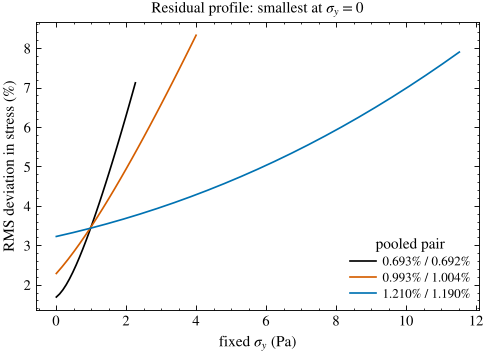

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
cols = [C["black"], C["red"], C["blue"]]
for (a, b), col in zip(PAIRS, cols):
    sw, gw = pooled((a, b))
    sy_grid = np.linspace(0, 0.8 * sw.min(), 25)
    prof = [hb_fit(sw, gw, sy_bounds=(s, s + 1e-12))["rms_log"] for s in sy_grid]
    ax.plot(sy_grid, 100 * np.array(prof), color=col, label=f"{a[1]:.3f}% / {b[1]:.3f}%")
    free = hb_fit(sw, gw, sy_bounds=(-0.9 * sw.min(), sw.min()))
    print(f"{a[1]:.3f}%/{b[1]:.3f}%: unconstrained sigma_y = {free['sigma_y']:+.2f} Pa (n = {free['n']:.2f})")
ax.set_xlabel(r"fixed $\sigma_y$ (Pa)"); ax.set_ylabel("RMS deviation in stress (%)")
ax.set_title("Residual profile: smallest at $\\sigma_y = 0$", fontsize=10)
ax.legend(title="pooled pair", fontsize=8.5); plt.show()

## 6. Why the 1926 relation is a correlation and not a constitutive law

Section II C of the review gives the reasons; we can check each one with the data.

**(i) The only stress–rate reading in 1926 was a power law without a threshold.** A footnote credits H. L. Dryden with the observation that $q\propto P^a$ follows from a shear stress proportional to the shear rate raised to the power $1/a$. So the 1926 exponent $a$ corresponds to a modern flow index $n = 1/a$, with no yield stress. Compare $1/a$ from Table IV with the refitted $n$:

In [14]:
rows = []
for (a_, b_), f in zip(PAIRS, fits.itertuples()):
    ra, rb = table4_row(*a_), table4_row(*b_)
    rows.append({"pair": f.pair, "1/a, Nr. 3": 1 / ra.a, "1/a, Nr. 2": 1 / rb.a,
                 "P0 (Nr. 2), gf/cm^2": rb.P0_gf_per_cm2, "refitted n": f.n})
pd.DataFrame(rows).round(3)

,pair,"1/a, Nr. 3","1/a, Nr. 2","P0 (Nr. 2), gf/cm^2",refitted n
0,0.693% (Nr. 3) + 0.692% (Nr. 2),0.813,0.813,0,0.809
1,0.993% (Nr. 3) + 1.004% (Nr. 2),0.746,0.752,10,0.739
2,1.210% (Nr. 3) + 1.190% (Nr. 2),0.690,0.704,15,0.677


In every case $1/a$ is within about 0.03 of the refitted $n$: the 1926 exponents already encoded the shear thinning, and the small differences reflect the initial pressures and the Newtonian $d^4/L$ scaling discussed next.

**(ii) Geometry: the factor $d^4/L$ is the Newtonian one.** For a no-slip power-law liquid with index $n = 1/a$, the exact capillary flow rate is

$$q = \frac{\pi n}{3n+1}\left(\frac d2\right)^3\left(\frac{P d}{4LK}\right)^{1/n} \propto d^{\,3+a}L^{-a}P^{\,a}, \tag{2}$$

so Eq. (1) holds exactly only for $a = 1$; otherwise $I \propto d^4P^a/(Lq) \propto d^{\,1-a}L^{\,a-1}$ absorbs a weak dependence on capillary size. For the 0.69% solution (both fits with $P_0 = 0$) we can compare the predicted and printed ratio of $I$ between the two capillaries. This comparison is our own illustration of the statement in the review.

In [15]:
r3, r2 = table4_row("B3", 0.693), table4_row("B2", 0.692)
(d3, L3), (d2, L2) = DIM["B3"], DIM["B2"]
a_mean = 0.5 * (r3.a + r2.a)
pred = (d3 / d2)**(1 - a_mean) * (L3 / L2)**(a_mean - 1)
print(f"a = {a_mean:.2f}: Eq. (2) predicts I(Nr. 3)/I(Nr. 2) = {pred:.3f}; Table IV gives {r3.I / r2.I:.3f}")
print("A Newtonian liquid (a = 1) would give exactly 1.")

a = 1.23: Eq. (2) predicts I(Nr. 3)/I(Nr. 2) = 0.838; Table IV gives 0.879
A Newtonian liquid (a = 1) would give exactly 1.


**(iii) Near onset, a yield stress changes the exponent.** If the rubber solutions had a yield stress, the flow rate just above the threshold would grow as the excess wall stress $\delta = \sigma_w - \sigma_y$ to the power $1+1/n$, Eq. (24), and only far above it as $\sigma_w^{1/n}$, Eq. (25):

$$Q\sim\frac{\pi R^3 n}{(n+1)K^{1/n}\sigma_y}\,\delta^{1+1/n}\quad(\delta\ll\sigma_y),\qquad Q\sim\frac{\pi R^3 n}{3n+1}\left(\frac{\sigma_w}{K}\right)^{1/n}\quad(\sigma_w\gg\sigma_y).$$

A shifted power law $q\propto(P-P_0)^a$ has a single exponent and therefore cannot represent an HB fluid over the whole pressure range. The local slope $\mathrm d\ln Q/\mathrm d\ln\delta$ of the exact solution shows the crossover:

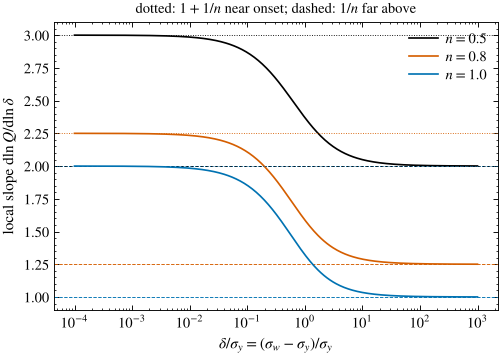

In [16]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
R_ = 5e-4; sy_, K_ = 1.0, 0.05
for n_, col in [(0.5, C["black"]), (0.8, C["red"]), (1.0, C["blue"])]:
    delta = np.logspace(-4, 3, 400) * sy_            # excess wall stress
    Q = pipe_flux(sy_ + delta, R_, sy_, K_, n_)
    slope = np.gradient(np.log(Q), np.log(delta))
    ax.semilogx(delta / sy_, slope, color=col, label=f"$n={n_}$")
    ax.axhline(1 + 1 / n_, color=col, lw=0.6, ls=":"); ax.axhline(1 / n_, color=col, lw=0.6, ls="--")
    assert abs(slope[0] - (1 + 1 / n_)) < 0.01 and abs(slope[-1] - 1 / n_) < 0.05
ax.set_xlabel(r"$\delta/\sigma_y = (\sigma_w-\sigma_y)/\sigma_y$")
ax.set_ylabel(r"local slope $\mathrm{d}\ln Q/\mathrm{d}\ln\delta$")
ax.set_title("dotted: $1+1/n$ near onset; dashed: $1/n$ far above", fontsize=9.5)
ax.legend(); plt.show()

Read in today's terms, then, the rubber solutions were shear-thinning liquids with flow indices 0.68–0.81 whose data give no evidence of a yield stress; the two nonzero initial pressures are wall-stress offsets of 1–2 Pa that the pooled data do not require. The 1926 papers gave the field a *form*. Rheometric inversion (Rabinowitsch 1929, Mooney 1931; Table III of the review) and the tensorial theory of Hohenemser, Prager and Oldroyd (Sec. II D) were needed to make it a law.

## 7. Reproducing Fig. 1 and checking it against the figure data

We now redraw both panels of Fig. 1 and compare every plotted point with `data/figure_data/fig01_hb1926.csv`, which `scripts/fig01_hb1926.py` wrote when it made the published figure.

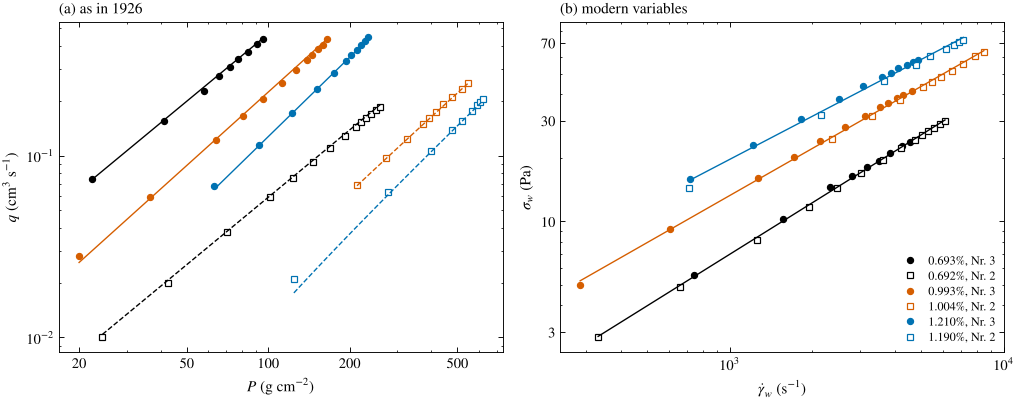

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
mine = []          # (panel, series, x, y) of everything we draw, for the check below
for (a_, b_), col, f in zip(PAIRS, cols, fits.itertuples()):
    for j, (inst, conc) in enumerate((a_, b_)):
        s = series(inst, conc)
        mk, mfc = ("o", col) if inst == "B3" else ("s", "white")
        name = f"{conc:.3f}%, {'Nr. 3' if inst == 'B3' else 'Nr. 2'}"
        # (a) the 1926 representation with the Table IV fit
        ax1.loglog(s.P_g_per_cm2, s.q_cm3_per_s, mk, color=col, mfc=mfc, ms=4, mew=0.8)
        r = table4_row(inst, conc); d, L = DIM[inst]
        Pg = np.logspace(np.log10(max(s.P_g_per_cm2.min(), r.P0_gf_per_cm2 + 1)), np.log10(s.P_g_per_cm2.max()), 50)
        ax1.loglog(Pg, q_1926(Pg, d, L, r.a, r.I, r.P0_gf_per_cm2), ["-", "--"][j], color=col, lw=0.9)
        mine += [("(a)", name + ": data of 1926 Table III", s.P_g_per_cm2.values, s.q_cm3_per_s.values),
                 ("(a)", name + ": 1926 fit, Table IV constants", Pg, q_1926(Pg, d, L, r.a, r.I, r.P0_gf_per_cm2))]
        # (b) wall variables
        ax2.loglog(s.gdot_w, s.sigma_w_Pa, mk, color=col, mfc=mfc, ms=4, mew=0.8, label=name)
        mine.append(("(b)", name, s.gdot_w.values, s.sigma_w_Pa.values))
    sw, gw = pooled((a_, b_))
    gg = np.logspace(np.log10(gw.min()), np.log10(gw.max()), 60)
    ax2.loglog(gg, f.sigma_y + f.K * gg**f.n, "-", color=col, lw=0.9)
    mine.append(("(b)", f"HB fit to the pooled data, {a_[1]:.3f}% and {b_[1]:.3f}%", gg, f.sigma_y + f.K * gg**f.n))
ax1.set_xlabel(r"$P$ (g cm$^{-2}$)"); ax1.set_ylabel(r"$q$ (cm$^3$ s$^{-1}$)"); ax1.set_title("(a) as in 1926", loc="left")
ax2.set_xlabel(r"$\dot\gamma_w$ (s$^{-1}$)"); ax2.set_ylabel(r"$\sigma_w$ (Pa)"); ax2.set_title("(b) modern variables", loc="left")
ax2.legend(fontsize=8, loc="lower right")
from matplotlib.ticker import NullFormatter
for ax in (ax1, ax2):
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
ax1.set_xticks([20, 50, 100, 200, 500]); ax1.set_xticklabels(["20", "50", "100", "200", "500"])
ax2.set_yticks([3, 10, 30, 70]); ax2.set_yticklabels(["3", "10", "30", "70"])
fig.tight_layout(); plt.show()

In [18]:
ref = pd.read_csv(FIGDATA / "fig01_hb1926.csv", comment="#")
worst = 0.0
for panel, name, x, y in mine:
    r = ref[(ref.panel == panel) & (ref.series == name)].sort_values("index")
    assert len(r) == len(x), (panel, name)
    # points are stored in plotting order (each series sorted by pressure, as here)
    dev = max(np.max(np.abs(r.x.values / x - 1)), np.max(np.abs(r.y.values / y - 1)))
    worst = max(worst, dev)
assert worst < 1e-6
plotted = w[[any(np.isclose(c, k[1]) and i == k[0] for k in sum(map(list, PAIRS), []))
             for i, c in zip(w.instrument, w.conc_pct)]]
print(f"plotted series: sigma_w = {plotted.sigma_w_Pa.min():.1f}-{plotted.sigma_w_Pa.max():.0f} Pa, "
      f"gdot_w = {plotted.gdot_w.min():.0f}-{plotted.gdot_w.max():.0f} 1/s (article: 2.8-72 Pa, 3e2-8e3 1/s)")
print(f"Fig. 1: all {len(mine)} series ({sum(len(m[2]) for m in mine)} points) agree with "
      f"fig01_hb1926.csv; largest relative difference {worst:.1e} (tolerance 1e-6)")

plotted series: sigma_w = 2.8-72 Pa, gdot_w = 285-8468 1/s (article: 2.8-72 Pa, 3e2-8e3 1/s)
Fig. 1: all 21 series (610 points) agree with fig01_hb1926.csv; largest relative difference 2.0e-09 (tolerance 1e-6)


## Try it yourself

**Exercise 1 — the Ostwald viscometers.** Table IV also contains fits for two Ostwald viscometers, all with $P_0 = 0$. Compute the equivalent flow index $1/a$ for every concentration and plot it against concentration together with the three refitted $n$ of Sec. 5. Does shear thinning increase with concentration?
*Hint:* `t4[t4.instrument.str.startswith("Ostwald")]`.

<details><summary>Solution (click to expand)</summary>

```python
ost = t4[t4.instrument.str.startswith("Ostwald")]
for name, g in ost.groupby("instrument"):
    plt.plot(g.conc_pct, 1 / g.a, "o-", label=name)
plt.plot([0.6925, 0.9985, 1.2], fits.n, "k*", ms=10, label="refitted n (Bingham)")
plt.xlabel("concentration (%)"); plt.ylabel("flow index"); plt.legend(); plt.show()
```
$1/a$ falls from about 0.90 at 0.2% to 0.66 at 1.19%: the more concentrated solutions are more shear-thinning, consistent with the refitted indices.
</details>

**Exercise 2 — one capillary at a time.** Fit the HB law to each of the ten Bingham series (six in Nr. 3, four in Nr. 2) *separately*, not pooled. Is $\sigma_y$ still zero? Do the two capillaries give the same $n$ at matched concentration? What would a difference tell you about wall slip?
*Hint:* reuse `hb_fit(s.sigma_w_Pa.values, s.gdot_w.values)` inside a loop over `w.groupby(["instrument", "conc_pct"])`.

<details><summary>Solution</summary>

```python
rows = []
for (inst, conc), s in w.groupby(["instrument", "conc_pct"]):
    f = hb_fit(s.sigma_w_Pa.values, s.gdot_w.values)
    rows.append({"instrument": inst, "conc_pct": conc, "sigma_y (Pa)": f["sigma_y"], "n": f["n"],
                 "rms (%)": 100 * f["rms_log"]})
pd.DataFrame(rows).round(3)
```
Eight of the ten single-series fits land on $\sigma_y = 0$; the other two give 0.11 Pa (0.692%, Nr. 2) and 1.9 Pa (1.004%, Nr. 2, the series whose Table IV fit has $P_0 = 10$ gf cm$^{-2}$), offsets that the pooled fits do not need. At matched concentration the two capillaries give $n$ = 0.80 and 0.82 (0.69%), 0.76 and 0.78 (about 1.0%) and 0.68 and 0.70 (about 1.2%): differences of about 0.02, small compared with the change of $n$ between concentrations, and the pooled fits describe both capillaries with 1.7–3.2% scatter in stress. Slip at the glass would make the narrower capillary (Nr. 2) carry more flow at the same wall stress, so the two curves would separate in a systematic way, increasingly at low stress; such separation is not seen, which is Reiner's (1931) argument for no slip. A single series cannot test slip on its own: that needs two or more diameters (notebook 06).
</details>

**Exercise 3 — the derivative matters.** The WRM correction needs $n'$. Replace the local quadratic slope by a single straight-line slope per series (`np.polyfit(x, y, 1)[0]`), redo the pooled fits, and compare the flow indices. How large is the change compared with the differences between concentrations?

<details><summary>Solution</summary>

```python
def wrm_linear(series):
    x, y = np.log(series.gdot_app.values), np.log(series.sigma_w_Pa.values)
    nprime = np.polyfit(x, y, 1)[0]                        # one slope per series
    return series.gdot_app.values * (3 * nprime + 1) / (4 * nprime)

w_lin = w.copy()
for key, s in w.groupby(["instrument", "conc_pct"]):
    w_lin.loc[s.index, "gdot_w"] = wrm_linear(s)
for a_, b_ in PAIRS:
    s = pd.concat([w_lin[(w_lin.instrument == i) & np.isclose(w_lin.conc_pct, c)] for i, c in (a_, b_)])
    f = hb_fit(s.sigma_w_Pa.values, s.gdot_w.values)
    print(a_[1], b_[1], round(f["n"], 3), f["sigma_y"])
```
With a single slope per series the pooled fits give $n$ = 0.810, 0.741 and 0.688 (against 0.809, 0.739 and 0.677 with the local quadratic slope), and $\sigma_y$ stays at zero. The change, at most 0.011, is far smaller than the difference of about 0.07 between neighboring concentrations, because $n'$ varies little within each series (Sec. 4). It would matter more for a material with a yield stress, where $n'$ changes strongly along the curve.
</details>

**Exercise 4 — could the 1926 method have detected a yield stress?** Generate synthetic "1926" data for an HB fluid with $\sigma_y = 1.5$ Pa (the size of the 1926 offsets), $K = 0.08$ Pa s$^n$ and $n = 0.74$ in the capillary Nr. 2, over the same wall-stress range as the 1.004% series, using `pipe_flux` (convert to SI). Apply Secs. 3–5 to them. Is the yield stress recovered? Does a plot of $\log q$ against $\log P$ look straight?

<details><summary>Hint for Exercise 4</summary>

`R = 0.0689e-2 / 2` m; choose `sw = np.linspace(25, 63, 10)` Pa; `Q = pipe_flux(sw, R, 1.5, 0.08, 0.74)` m³/s; then $P = 4L\sigma_w/d$ and $q = 10^6 Q$ cm³/s.
</details>

<details><summary>Solution</summary>

```python
dB2, LB2 = DIM["B2"]                                   # cm
R = dB2 / 2 * 1e-2                                     # m
sw = np.linspace(25, 63, 10)                           # Pa
Q = pipe_flux(sw, R, 1.5, 0.08, 0.74)                  # m^3/s
syn = pd.DataFrame({"instrument": "B2", "conc_pct": 0.0,
                    "P_g_per_cm2": 4 * LB2 * sw / dB2 / GF_PER_CM2,   # P = 4 L sigma_w / d, in gf/cm^2
                    "q_cm3_per_s": 1e6 * Q})
ws = to_wall_variables(syn)
ws["gdot_w"], ws["n_prime"] = wrm(ws)
print(hb_fit(ws.sigma_w_Pa.values, ws.gdot_w.values))
line = np.polyfit(np.log(syn.P_g_per_cm2), np.log(syn.q_cm3_per_s), 1)
dev = np.log(syn.q_cm3_per_s) - np.polyval(line, np.log(syn.P_g_per_cm2))
print("log q vs log P: slope", line[0], " rms deviation from a straight line (%)", 100 * np.sqrt(np.mean(dev**2)))
# the same with 2% random error on q, 200 repetitions
rng = np.random.default_rng(1)
sy_noisy = []
for _ in range(200):
    s2 = syn.copy(); s2["q_cm3_per_s"] *= np.exp(0.02 * rng.standard_normal(len(s2)))
    w2 = to_wall_variables(s2); w2["gdot_w"], w2["n_prime"] = wrm(w2)
    sy_noisy.append(hb_fit(w2.sigma_w_Pa.values, w2.gdot_w.values)["sigma_y"])
print("2.5-97.5% range of sigma_y:", np.quantile(sy_noisy, [0.025, 0.975]), " fits at sigma_y = 0:", np.mean(np.array(sy_noisy) < 1e-3))
```
With exact synthetic data the procedure returns $\sigma_y \approx 1.9$ Pa, $K \approx 0.074$ Pa s$^n$ and $n \approx 0.75$ (true: 1.5 Pa, 0.08 Pa s$^{0.74}$, 0.74): the yield stress is found, but biased by about 25%, because the quadratic estimate of $n'$ is not exact. The plot of $\log q$ against $\log P$ looks straight: a line of slope 1.42 fits it to within 0.3%, so the 1926 representation hides the yield stress. With a realistic 2% error on $q$ the fitted $\sigma_y$ ranges from 0 to about 7 Pa (central 95%), and about a third of the fits land on $\sigma_y = 0$. At wall rates of 2000–8000 s$^{-1}$ a yield stress of 1.5 Pa cannot be resolved, which is the conclusion of Sec. II C of the review.
</details>

## Key points
- The 1926 data are pressure–flow-rate pairs in gf cm$^{-2}$ and cm$^3$ s$^{-1}$; $1\ \mathrm{gf\,cm^{-2}} = 98.0665$ Pa.
- Wall shear stress follows from a force balance, $\sigma_w = Pd/4L$, without any constitutive assumption; $32q/\pi d^3$ is only the *apparent* wall shear rate.
- The Weissenberg–Rabinowitsch–Mooney correction $\dot\gamma_w = \dot\gamma_{\rm app}(3n'+1)/4n'$ gives the true wall rate for no-slip laminar flow, at the cost of differentiating data.
- Refitted in modern variables, with $\sigma_y\ge0$, the pooled data of both capillaries give $\sigma_y = 0$ and $n = 0.81$, 0.74 and 0.68, with 1.7–3.2% scatter in stress: the rubber solutions were shear-thinning liquids whose data give no evidence of a yield stress.
- The 1926 relation is an instrument correlation: its stress–rate reading was a power law ($n = 1/a$), its $d^4/L$ scaling is Newtonian, a shifted power law cannot follow the change of exponent near onset, and the authors themselves said that $P_0$ is not a material constant.

## References

The review and its repository:
- Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

- W. H. Herschel and R. Bulkley (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
- W. H. Herschel and R. Bulkley (1926). Measurement of consistency as applied to rubber-benzene solutions. *Proceedings of the American Society for Testing Materials* **26**, 621–633.
- M. Reiner (1931). Slippage in a non-Newtonian liquid. *Journal of Rheology* **2**, 337–350. https://doi.org/10.1122/1.2116393
- B. Rabinowitsch (1929). Über die Viskosität und Elastizität von Solen. *Zeitschrift für Physikalische Chemie* **145A**, 1–26. https://doi.org/10.1515/zpch-1929-14502
- M. Mooney (1931). Explicit Formulas for Slip and Fluidity. *Journal of Rheology* **2**, 210–222. https://doi.org/10.1122/1.2116364
- K. Hohenemser and W. Prager (1932). Über die Ansätze der Mechanik isotroper Kontinua. *ZAMM – Zeitschrift für Angewandte Mathematik und Mechanik* **12**, 216–226. https://doi.org/10.1002/zamm.19320120403
- J. G. Oldroyd (1947). A rational formulation of the equations of plastic flow for a Bingham solid. *Mathematical Proceedings of the Cambridge Philosophical Society* **43**, 100–105. https://doi.org/10.1017/s0305004100023239
- A. B. Metzner and J. C. Reed (1955). Flow of non-Newtonian fluids—correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409

### Further reading

- W. H. Herschel (1924). Consistency of Rubber Benzene Solutions. *Industrial & Engineering Chemistry* **16**, 927. https://doi.org/10.1021/ie50177a019
- E. C. Bingham (1916). An investigation of the laws of plastic flow. *Bulletin of the Bureau of Standards* **13**, 309–353. https://doi.org/10.6028/bulletin.304
- E. Buckingham (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
- R. B. Bird, G. C. Dai and B. J. Yarusso (1983). The Rheology and Flow of Viscoplastic Materials. *Reviews in Chemical Engineering* **1**, 1–70. https://doi.org/10.1515/revce-1983-0102
- R. P. Chhabra and J. F. Richardson (2008). Non-Newtonian Flow and Applied Rheology: Engineering Applications. 2nd ed., Butterworth-Heinemann, Oxford.